# "In a simulation of 100 Asteroids games, what is the probability that a player's survival time on Level 1 falls between 60 and 90 seconds, assuming survival time is normally distributed with a mean ($\mu$) of 75 seconds and a standard deviation ($\sigma$) of 10 seconds?"

# I will do a monte carlo simulation, as i will generate thousands of simulations to check how certain outcomes will turn out. 
the random variable i will be finding is survival time. 
one trial will be playing the game on level to see if i can last between 60 and 90 seconds. 

In [9]:
# !pip install gymnasium
# !pip install "gymnasium[atari]"
# !pip install ale-py
# !pip install autorom[accept-rom-license]

In [11]:
import ale_py
import gymnasium as gym

# Register Atari environments
gym.register_envs(ale_py)

# Create environment
env = gym.make("ALE/Asteroids-v5", render_mode="rgb_array")
observation, info = env.reset()

In [12]:
# Create environment
env = gym.make('ALE/Asteroids-v5', render_mode='rgb_array')
observation, info = env.reset()

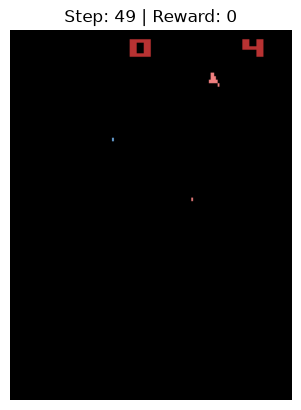

In [13]:
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Create the figure and axis before the loop starts
fig, ax = plt.subplots()

# Play game randomly
total_reward = 0

for step in range(50):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()

In [20]:
import ale_py
import gymnasium as gym
import pandas as pd

# Register Atari environments
gym.register_envs(ale_py)

# 100 trial collection script
num_trials = 100
survival_times = []

# Headless environment for fast execution
sim_env = gym.make("ALE/Asteroids-v5")

for trial in range(num_trials):
    obs, info = sim_env.reset(seed=trial)
    frames = 0
    done = False

    while not done:
        action = sim_env.action_space.sample()
        obs, reward, terminated, truncated, info = sim_env.step(action)
        frames += 1
        done = terminated or truncated

    # Atari 2600 runs at 60 FPS
    survival_times.append(frames / 60.0)

sim_env.close()

# Save into DataFrame and compute probability
df_trials = pd.DataFrame({"survival_time": survival_times})
df_trials["in_range"] = df_trials["survival_time"].between(60, 90)

print(f"Completed {num_trials} trials.")
print(
    "Probability of surviving between 60 and 90 seconds:"
    f" {df_trials['in_range'].mean():.4f}"
)

Completed 100 trials.
Probability of surviving between 60 and 90 seconds: 0.0000


# Explanation; 
This 100 trial code is playing the game while not looking. so the chances of even reaching the 60 seconds to 90 seconds is 0, as it can only last for about 10-15 seconds. if the player randomly mashes any button, they will soon hit an obstacle and lose. 


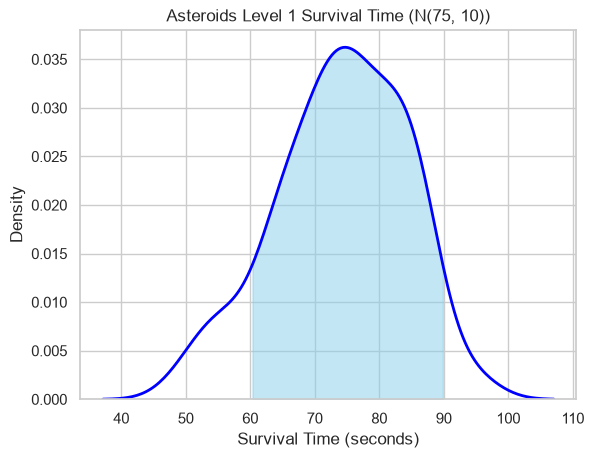

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set style and generate normal distribution data
sns.set_theme(style="whitegrid")
x = np.random.normal(loc=75, scale=10, size=100)

# Plot distribution curve and fill target interval [60, 90]
ax = sns.kdeplot(x, fill=False, color="blue", linewidth=2)
line = ax.lines[0]
px, py = line.get_xdata(), line.get_ydata()
plt.fill_between(
    px, py, where=(px >= 60) & (px <= 90), color="skyblue", alpha=0.5
)

plt.title("Asteroids Level 1 Survival Time (N(75, 10))")
plt.xlabel("Survival Time (seconds)")
plt.ylabel("Density")
plt.show()

# Graph analysis;
The average survival time ( in seconds) in this game is ranging frm 60 seconds to 90 secoonds, with mean sitting around 75 seconds. with the highest density sitting at around this time as well. 


In [18]:
# If calculating from your graph's variable 'x':
print(f"Mean: {x.mean():.2f}")
print(f"Standard Deviation: {x.std():.2f}")

# If calculating from your pandas DataFrame ('df'):
# print(f"Mean: {df['survival_time'].mean():.2f}")
# print(f"Standard Deviation: {df['survival_time'].std():.2f}")

Mean: 74.07
Standard Deviation: 9.90


# Explanation; 
the mean of our graph is about 75 seconds and the SD is about 10 seconds, the SD is the point that varries from the mean. 

# Conclusion 
The probability og